In [1]:
import numpy as np

### Numpy basics

1\. Find the row, column and overall means for the following matrix:

```python
m = np.arange(12).reshape((3,4))
```

In [2]:
def mean_row(m):
    row_m = []
    for i in range(m.shape[0]):
        r_m = m[i].mean()
        row_m.append(r_m)
    
    mean_r = np.mean(row_m)
    return print(mean_r)

def mean_col(m):
    col_m = []
    for i in range(m.shape[1]):
        c_m = m[:, i].mean()
        col_m.append(c_m)
    mean_c = np.mean(col_m)
    return print(mean_c)
        

def o_mean(m):
    return print(m.mean())

In [3]:
m = np.arange(12).reshape((3,4))
mean_row(m)
mean_col(m)
o_mean(m)

5.5
5.5
5.5


2\. Find the outer product of the following two vecotrs

```python
u = np.array([1,3,5,7])
v = np.array([2,4,6,8])
```

Do this in the following ways:

   * Using the function outer in numpy
   * Using a nested for loop or list comprehension
   * Using numpy broadcasting operatoins


In [4]:
# with numpy
def oute(u,v):
    return print(np.outer(u,v))

# with nested loop
def loop_out(u,v):
    nrows = len(u)
    ncolumns = len(v)
    fin_matrix = np.zeros((nrows, ncolumns))
    for i in range(nrows):
        u_i = u[i]
        for j in range(ncolumns):
            fin_matrix[i][j] = u_i * v[j]
    
    return print(fin_matrix)

# with numpy broadcasting
def broad_out(u,v):
    new_u = np.tile(u, (len(u), 1))
    return print(np.transpose(new_u) * v)    

In [5]:
u = np.array([1, 3, 5, 7])
v = np.array([2,4,6,8])
# outerproduct es u por v transpuesta
oute(u,v)
loop_out(u,v)
broad_out(u,v)

[[ 2  4  6  8]
 [ 6 12 18 24]
 [10 20 30 40]
 [14 28 42 56]]
[[ 2.  4.  6.  8.]
 [ 6. 12. 18. 24.]
 [10. 20. 30. 40.]
 [14. 28. 42. 56.]]
[[ 2  4  6  8]
 [ 6 12 18 24]
 [10 20 30 40]
 [14 28 42 56]]


3\. Create a 10 by 6 matrix of random uniform numbers. Set all rows with any entry less than 0.1 to be zero

Hint: Use the following numpy functions - np.random.random, np.any as well as Boolean indexing and the axis argument.

In [6]:
import numpy.random as npr
npr.seed(123)

In [7]:
# any version
m = npr.rand(2, 3)
print(m)
fila_mask = np.any(m < 0.1, axis=1) #Creamos mascara 
# axis=1 verifica si "cualquier" elemento de la fila es < 0.1, con que uno lo cumpla la fila entera se pondra en true
# no solo el elemento de la fila

m[fila_mask] = 0 # ponemos en cero las filas que cumplen la condicion, es decir, true
print(m)

[[0.69646919 0.28613933 0.22685145]
 [0.55131477 0.71946897 0.42310646]]
[[0.69646919 0.28613933 0.22685145]
 [0.55131477 0.71946897 0.42310646]]


4\. Use np.linspace to create an array of 100 numbers between 0 and 2π (includsive).

  * Extract every 10th element using slice notation
  * Reverse the array using slice notation
  * Extract elements where the absolute difference between the sine and cosine functions evaluated at that element is less than 0.1
  * Make a plot showing the sin and cos functions and indicate where they are close

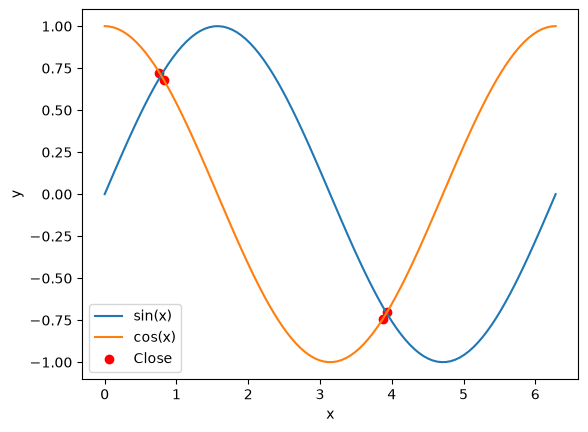

[0.76159822 0.82506474 3.87145761 3.93492413]


In [15]:
# creamos array de 100 datos
a = np.linspace(0, 2*np.pi, 100)

# utilizando slice notation extrameos cada decimo elemento
# array[inicio:final:paso], en donde icnio y final lo dejamos vacio y solo ponemos 10 en paso
a_10 = a[::10]

# -1 indica que queremos recorrer el indice en sentdio contrario
a_reverse = a[::-1]


# Primero calculamos sin y cos en los valores de a
sin_a = np.sin(a)
cos_a = np.cos(a)

# toammos el valor absoluto de su difernecia
difference = np.abs(sin_a - cos_a)

# creamos una mascara para iadentificar los valores que sean menor a 0.1
mask = difference < 0.1

# aplicamos la mascara a a
a_close = a[mask]

# por ultimo graficamos
import matplotlib.pyplot as plt

plt.plot(a, sin_a, label='sin(x)')
plt.plot(a, cos_a, label='cos(x)')

# en este caso a_close, contiene los puntos mas cercanos entre sin y coseno dado que su difernecia es menor a 0.1
# colocando los puntos rojos sobre la curva del coseno, pero únicamente en las posiciones donde ambas funciones son cercanas
plt.scatter(a_close, np.cos(a_close), color='red', label='Close')

plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

print(a_close)

5\. Create a matrix that shows the 10 by 10 multiplication table.

 * Find the trace of the matrix
 * Extract the anto-diagonal (this should be ```array([10, 18, 24, 28, 30, 30, 28, 24, 18, 10])```)
 * Extract the diagnoal offset by 1 upwards (this should be ```array([ 2,  6, 12, 20, 30, 42, 56, 72, 90])```)

In [24]:
# usamos from function para crear una matriz que tenga las tablas de multplicar segun su fila/columna
ten_by_ten = np.fromfunction(lambda i, j: (i+1)*(j+1), (10, 10))

# usamos numpy para sacar la traza
trace = np.trace(ten_by_ten)

# o hacerlo manualmente
# trace = 0
# for i in range(len(ten_by_ten)):
#     trace += ten_by_ten[i, i]

#para extraer la antigiaonal
# primero invertimos la matriz con fliplr, y luego sacamos la diagonal principal que es la antidiagonal
anti_diagonal = np.diag(np.fliplr(ten_by_ten))

# extraemos la diagonal con offset de uno arriba
diagonal_up = np.diag(ten_by_ten, k=1)
# k=1 indicamos que queremos la diagonal que esta una posicion encima de la principal

6\. Use broadcasting to create a grid of distances

Route 66 crosses the following cities in the US: Chicago, Springfield, Saint-Louis, Tulsa, Oklahoma City, Amarillo, Santa Fe, Albuquerque, Flagstaff, Los Angeles
The corresponding positions in miles are: 0, 198, 303, 736, 871, 1175, 1475, 1544, 1913, 2448

  * Construct a 2D grid of distances among each city along Route 66
  * Convert that in km (those savages...)

In [28]:
# Tenemos la posicion de las ciudades en un array
positions = np.array([0, 198, 303, 736, 871, 1175, 1475, 1544, 1913, 2448])

# Calculamos la distancia entre cada par de ciudades, en donde tomamos el valor absoluto de la resta entre position - su transpuesta
# asi el broadcasting sera restar uno a uno, el primero con el primero, el primero con el segundo,-- el primero conel ultimo y asi sucesvametne
distances = np.abs(positions - positions[:, np.newaxis])

# Para pasarlos a kilometros solo multimplicamos por su equialevente
# 1 mile = 1.60934 km
distances_km = distances * 1.60934

7\. Prime numbers sieve: compute the prime numbers in the 0-N (N=99 to start with) range with a sieve (mask).
  * Constract a shape (100,) boolean array, the mask
  * Identify the multiples of each number starting from 2 and set accordingly the corresponding mask element
  * Apply the mask to obtain an array of ordered prime numbers
  * Check the performances (timeit); how does it scale with N?
  * Implement the optimization suggested in the [sieve of Eratosthenes](https://en.wikipedia.org/wiki/Sieve_of_Eratosthenes)

In [10]:
import timeit

N = 99

def sieve(N):
    # primero construimos la mascara, que inicializa el array todos en true 
    mask = np.ones(N+1, dtype=bool)

    # Inicializamos los primero dos primos
    mask[0] = False
    mask[1] = False

# para  i de 2 hasta la raiz entera de N + 1
    for i in range(2, int(np.sqrt(N)) + 1):
        if mask[i]: # si la mascara esta en True, es decir, aun no se ha seteado, ponemos false, ( es decir ya no se va a contar para el
            # siguietne loop)
            mask[i*i::i] = False # se van a poner en false los multilpos de i, emepezando a partir de su cuadrado
            # por ejemplo si tenemos 3, este empieza en 9, y da paso de 3 en 3 y los va poniendo en false

    return np.arange(N+1)[mask] # regresamos el array de 0 a 100 con la mascara apilcada, es decir, solo los que tiene True, que en este caso
# son los primos

primes = sieve(N)

print("Prime numbers:", primes)

# Medimos el tiempo de ejecucion
def run_sieve():
    sieve(N)

for N in [99, 999, 9999, 99999]:
    execution_time = timeit.timeit(run_sieve, number=10)
    print("N =", N, "Time =", execution_time/10)


Prime numbers: [ 2  3  5  7 11 13 17 19 23 29 31 37 41 43 47 53 59 61 67 71 73 79 83 89
 97]
N = 99 Time = 6.856999825686217e-05
N = 999 Time = 6.136000156402588e-05
N = 9999 Time = 0.00010441999766044318
N = 99999 Time = 0.0005063899967353791


**N.B. the following exercises are meant to be solved only if you are familiar with the numpy random library. If not you can skip them (postponed for one of the next exercise sessions)**


8\. Diffusion using random walk

Consider a simple random walk process: at each step in time, a walker jumps right or left (+1 or -1) with equal probability. The goal is to find the typical distance from the origin of a random walker after a given amount of time. 
To do that, let's simulate many walkers and create a 2D array with each walker as a raw and the actual time evolution as columns

  * Take 1000 walkers and let them walk for 200 steps
  * Use randint to create a 2D array of size walkers x steps with values -1 or 1
  * Build the actual walking distances for each walker (i.e. another 2D array "summing on each raw")
  * Take the square of that 2D array (elementwise)
  * Compute the mean of the squared distances at each step (i.e. the mean along the columns)
  * Plot the average distances (sqrt(distance\*\*2)) as a function of time (step)
  
Did you get what you expected?

9\. Analyze a data file 
  * Download the population of hares, lynxes and carrots at the beginning of the last century.
    ```python
    ! wget https://www.dropbox.com/s/3vigxoqayo389uc/populations.txt
    ```

  * Check the content by looking within the file
  * Load the data (use an appropriate numpy method) into a 2D array
  * Create arrays out of the columns, the arrays being (in order): *year*, *hares*, *lynxes*, *carrots* 
  * Plot the 3 populations over the years
  * Compute the main statistical properties of the dataset (mean, std, correlations, etc.)
  * Which species has the highest population each year?

Do you feel there is some evident correlation here? [Studies](https://www.enr.gov.nt.ca/en/services/lynx/lynx-snowshoe-hare-cycle) tend to believe so.